In [1]:
# ============================================================
# 04_basic_cnn_classifier_v2 - Cell 1
# Imports, seed, dataset_final ke train/val/test CSVs load
# ============================================================

# PyTorch aur neural network modules import karta hai
import torch
import torch.nn as nn
import torch.optim as optim

# Dataset aur DataLoader (batches banane ke liye)
from torch.utils.data import Dataset, DataLoader

# PIL images open karne ke liye
from PIL import Image

# Pandas, NumPy, os, time, random
import pandas as pd
import numpy as np
import os
import time
import random

# Matplotlib graphs ke liye
import matplotlib.pyplot as plt

# Metrics: accuracy, macro F1, confusion matrix, classification report
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# Seed fix karta hai taaki results repeat ho sakein
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Laptop CPU-only hai, to device cpu set karta hai
device = torch.device("cpu")

# Paths (dataset_final)
PROJECT_DIR = r"C:\Projects\Internship_Learning"
DATASET_DIR = os.path.join(PROJECT_DIR, "dataset_final")
IMAGES_DIR = os.path.join(DATASET_DIR, "images")

# Pehle se bane split CSVs load karta hai (train_test_split use NAHI kar rahe)
train_df = pd.read_csv(os.path.join(DATASET_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(DATASET_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(DATASET_DIR, "test.csv"))

# Label ko number me map karta hai (purane notebook jaisa order: good=0, average=1, poor=2)
label_map = {"good": 0, "average": 1, "poor": 2}

# Class names ki list (index order label_map ke hisaab se)
CLASS_NAMES = ["good", "average", "poor"]

# Versions aur sizes print karta hai
print("PyTorch version:", torch.__version__)
print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))

# Har split ka class distribution print karta hai
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, d["label"].value_counts().to_dict())

# Overlap check: koi filename do splits me common nahi hona chahiye
tr, va, te = set(train_df["filename"]), set(val_df["filename"]), set(test_df["filename"])
print("Overlap train-val:", len(tr & va), "| train-test:", len(tr & te), "| val-test:", len(va & te))

# Check karta hai ki saare filenames images folder me maujood hain
all_files = list(tr | va | te)
missing = [f for f in all_files if not os.path.exists(os.path.join(IMAGES_DIR, f))]
print("Missing images:", len(missing))

PyTorch version: 2.12.1+cpu
Train: 685 | Val: 147 | Test: 147
train {'average': 275, 'good': 223, 'poor': 187}
val {'average': 59, 'good': 48, 'poor': 40}
test {'average': 59, 'good': 48, 'poor': 40}
Overlap train-val: 0 | train-test: 0 | val-test: 0
Missing images: 0


In [2]:
# ============================================================
# 04_basic_cnn_classifier_v2 - Cell 2
# Images ko 224x224 pe resize karke cache, Dataset class aur DataLoaders
# ============================================================

# Purane notebook jaisa ImageNet normalization (mean/std)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Ek split ki saari images ko 224x224 uint8 tensor me load karne ka function
def load_split_images(df, split_name):

    # Start time
    t0 = time.time()

    # Har image ka uint8 array yahan jama hoga
    arrays = []

    # filenames ko plain Python list me leta hai
    files = df["filename"].tolist()

    # Har image pe loop
    for i, fname in enumerate(files, start=1):

        # Image open karke RGB me convert karta hai
        img = Image.open(os.path.join(IMAGES_DIR, fname)).convert("RGB")

        # 224x224 pe resize karta hai (purane notebook jaisa)
        img = img.resize((224, 224), Image.BILINEAR)

        # Numpy array (H, W, 3) me convert karke list me daalta hai
        arrays.append(np.asarray(img, dtype=np.uint8))

    # Saari images ko ek array (N, H, W, 3) me jodta hai
    arr = np.stack(arrays)

    # PyTorch format (N, 3, H, W) me permute karta hai
    tensor = torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()

    # Time print karta hai
    print(f"{split_name}: {tuple(tensor.shape)} loaded in {time.time() - t0:.1f} sec")
    return tensor

# Teeno splits ki images load karta hai
train_imgs = load_split_images(train_df, "train")
val_imgs = load_split_images(val_df, "val")
test_imgs = load_split_images(test_df, "test")

# Labels ko numeric tensor me convert karta hai (.tolist() se Arrow string issue nahi aata)
train_labels = torch.tensor([label_map[l] for l in train_df["label"].tolist()])
val_labels = torch.tensor([label_map[l] for l in val_df["label"].tolist()])
test_labels = torch.tensor([label_map[l] for l in test_df["label"].tolist()])


# Cached tensors se chalne wala Dataset class
class CachedDataset(Dataset):

    # Images aur labels store karta hai
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels

    # Total samples
    def __len__(self):
        return len(self.labels)

    # Ek sample: uint8 image ko 0-1 float me laata hai aur normalize karta hai
    def __getitem__(self, idx):
        img = self.images[idx].float() / 255.0
        img = (img - MEAN) / STD
        return img, self.labels[idx]

# Teeno splits ke datasets
train_dataset = CachedDataset(train_imgs, train_labels)
val_dataset = CachedDataset(val_imgs, val_labels)
test_dataset = CachedDataset(test_imgs, test_labels)

# DataLoaders: batch_size=8 (purane jaisa); sirf train shuffle hota hai
g = torch.Generator()
g.manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, generator=g)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

# Ek batch lekar shapes verify karta hai
xb, yb = next(iter(train_loader))
print("\nBatch images:", tuple(xb.shape), "| labels:", tuple(yb.shape))
print("Batch pixel range (normalize ke baad):", round(xb.min().item(), 2), "to", round(xb.max().item(), 2))
print("Loaders ready: train", len(train_loader), "| val", len(val_loader), "| test", len(test_loader), "batches")

train: (685, 3, 224, 224) loaded in 23.5 sec
val: (147, 3, 224, 224) loaded in 6.5 sec
test: (147, 3, 224, 224) loaded in 5.9 sec

Batch images: (8, 3, 224, 224) | labels: (8,)
Batch pixel range (normalize ke baad): -2.12 to 2.64
Loaders ready: train 86 | val 19 | test 19 batches


In [3]:
# ============================================================
# 04_basic_cnn_classifier_v2 - Cell 3
# SimpleCNN model (purane jaisa architecture), loss, optimizer
# ============================================================

# Purana SimpleCNN: 3 conv layers + 2 fully connected layers
class SimpleCNN(nn.Module):

    # Model ki layers define karta hai
    def __init__(self):
        super(SimpleCNN, self).__init__()

        # Convolution layers
        self.conv_layers = nn.Sequential(
            # 3 input channels (RGB) -> 16 feature maps
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            # Size aadha: 224 -> 112
            nn.MaxPool2d(2, 2),

            # 16 -> 32 feature maps
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            # Size aadha: 112 -> 56
            nn.MaxPool2d(2, 2),

            # 32 -> 64 feature maps
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            # Size aadha: 56 -> 28
            nn.MaxPool2d(2, 2),
        )

        # Fully connected layers
        self.fc_layers = nn.Sequential(
            # Feature maps ko 1D vector banata hai
            nn.Flatten(),
            # 64*28*28 features -> 256 neurons
            nn.Linear(64 * 28 * 28, 256),
            nn.ReLU(),
            # Overfitting kam karne ke liye dropout
            nn.Dropout(0.5),
            # Final output: 3 classes (good, average, poor)
            nn.Linear(256, 3),
        )

    # Forward pass
    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

# Seed dobara set karta hai taaki weights init repeatable ho
torch.manual_seed(SEED)

# Model ka object banata hai
model = SimpleCNN().to(device)

# Total parameters print karta hai
print("Total parameters:", sum(p.numel() for p in model.parameters()))

# Loss function: multi-class classification ke liye CrossEntropy
# Class imbalance (average zyada, poor kam) ke liye class weights (train counts ke inverse) use karta hai
train_counts = np.bincount(train_labels.numpy(), minlength=3)
class_weights = torch.tensor(len(train_labels) / (3 * train_counts), dtype=torch.float32)
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Adam optimizer, lr=0.001 (purane jaisa)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Class counts aur weights print karta hai (good, average, poor ke order me)
print("Train class counts [good, average, poor]:", train_counts.tolist())
print("Class weights:", [round(w, 3) for w in class_weights.tolist()])

# Ek batch pe forward pass check karta hai (output shape (8, 3) aani chahiye)
with torch.no_grad():
    out = model(xb)
print("Forward check output shape:", tuple(out.shape))

Total parameters: 12869667
Train class counts [good, average, poor]: [223, 275, 187]
Class weights: [1.024, 0.83, 1.221]
Forward check output shape: (8, 3)


In [4]:
# ============================================================
# 04_basic_cnn_classifier_v2 - Cell 4
# Training: har epoch pe VAL check, best val macro F1 ka checkpoint save (test nahi use hota)
# ============================================================

# Model weights save karne ka folder (project ke model folder me; ye GitHub pe nahi jayega)
MODEL_DIR = os.path.join(PROJECT_DIR, "model")
os.makedirs(MODEL_DIR, exist_ok=True)
BEST_PATH = os.path.join(MODEL_DIR, "cnn_scratch_v2_best.pth")

# Kisi bhi loader pe evaluate karne ka function: loss, accuracy, macro F1, preds, labels return karta hai
def evaluate(loader):

    # Model ko eval mode me daalta hai (dropout band)
    model.eval()

    # Total loss, predictions aur labels yahan jama honge
    total_loss = 0.0
    preds_all = []
    labels_all = []

    # Gradient calculation band (fast aur kam memory)
    with torch.no_grad():
        for images, labels in loader:

            # Forward pass
            outputs = model(images)

            # Batch loss (batch size se multiply karta hai taaki sahi average mile)
            total_loss += criterion(outputs, labels).item() * labels.size(0)

            # Highest score wali class = prediction
            preds_all.extend(outputs.argmax(dim=1).tolist())
            labels_all.extend(labels.tolist())

    # Average loss, accuracy aur macro F1
    avg_loss = total_loss / len(labels_all)
    acc = accuracy_score(labels_all, preds_all) * 100
    f1 = f1_score(labels_all, preds_all, average="macro") * 100
    return avg_loss, acc, f1, preds_all, labels_all

# Training settings
EPOCHS = 15

# History lists (graph ke liye)
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}

# Best val macro F1 aur uska epoch track karta hai
best_val_f1 = -1.0
best_epoch = 0

print("Training started...")
print("=" * 70)
start_time = time.time()

# Epoch loop
for epoch in range(1, EPOCHS + 1):

    # Model ko training mode me daalta hai
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    # Train data ko batch-wise process karta hai
    for images, labels in train_loader:

        # Forward pass
        outputs = model(images)

        # Loss calculate
        loss = criterion(outputs, labels)

        # Gradients clear, backward, weights update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Running stats update
        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    # Epoch ka train loss aur accuracy
    train_loss = running_loss / total
    train_acc = correct / total * 100

    # VAL pe evaluate karta hai
    val_loss, val_acc, val_f1, _, _ = evaluate(val_loader)

    # History me store
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    # Agar val macro F1 best hai to checkpoint save karta hai
    star = ""
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        torch.save(model.state_dict(), BEST_PATH)
        star = "  <-- best (saved)"

    # Epoch ka result print
    print(f"Epoch [{epoch:02d}/{EPOCHS}] train loss {train_loss:.3f} acc {train_acc:.1f}% | "
          f"val loss {val_loss:.3f} acc {val_acc:.1f}% F1 {val_f1:.1f}% | {time.time() - start_time:.0f}s{star}")

print("=" * 70)
print(f"Training complete. Best val macro F1: {best_val_f1:.2f}% at epoch {best_epoch}")
print("Checkpoint:", BEST_PATH)

Training started...
Epoch [01/15] train loss 1.157 acc 38.4% | val loss 1.075 acc 40.8% F1 31.6% | 18s  <-- best (saved)
Epoch [02/15] train loss 1.140 acc 40.6% | val loss 1.098 acc 40.1% F1 20.5% | 36s
Epoch [03/15] train loss 1.080 acc 42.9% | val loss 1.103 acc 36.7% F1 26.1% | 67s
Epoch [04/15] train loss 1.088 acc 40.9% | val loss 1.092 acc 38.1% F1 31.8% | 90s  <-- best (saved)
Epoch [05/15] train loss 1.067 acc 42.6% | val loss 1.094 acc 44.2% F1 37.1% | 109s  <-- best (saved)
Epoch [06/15] train loss 1.018 acc 49.8% | val loss 1.296 acc 34.0% F1 32.4% | 132s
Epoch [07/15] train loss 0.936 acc 58.1% | val loss 1.119 acc 38.1% F1 38.0% | 158s  <-- best (saved)
Epoch [08/15] train loss 0.804 acc 66.4% | val loss 1.293 acc 41.5% F1 41.2% | 178s  <-- best (saved)
Epoch [09/15] train loss 0.607 acc 76.1% | val loss 1.299 acc 42.9% F1 42.1% | 195s  <-- best (saved)
Epoch [10/15] train loss 0.368 acc 85.7% | val loss 1.532 acc 44.9% F1 43.4% | 212s  <-- best (saved)
Epoch [11/15] trai

Checkpoint epoch: 15
TEST accuracy: 38.10% | TEST macro F1: 37.72%

Confusion matrix (order good/average/poor):
[[15 18 15]
 [11 24 24]
 [12 11 17]]

Classification report:
              precision    recall  f1-score   support

        good      0.395     0.312     0.349        48
     average      0.453     0.407     0.429        59
        poor      0.304     0.425     0.354        40

    accuracy                          0.381       147
   macro avg      0.384     0.381     0.377       147
weighted avg      0.393     0.381     0.382       147

OLD CNN (200 imgs, test=40): acc 37.5% | macro F1 37.0%

SOURCE-WISE (test set):
Source  n  Acc (%)  Macro F1 (%)
   old 30     40.0          38.3
    b1 19     42.1          42.1
    b2 42     35.7          33.2
    b3 56     37.5          37.4

Wrong predictions: 91 of 147
Saved: C:\Projects\Internship_Learning\dataset_final\misclassified_cnn_scratch_test.csv


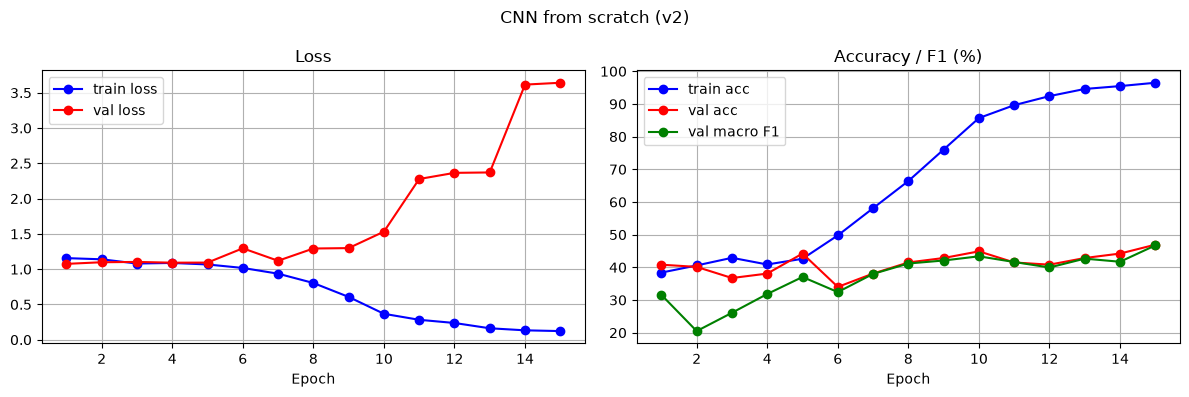

In [5]:
# ============================================================
# 04_basic_cnn_classifier_v2 - Cell 5
# FINAL TEST (sirf ek baar): best-val checkpoint load, metrics, source-wise, curves, misclassified CSV
# ============================================================

# Best-val checkpoint ke weights load karta hai
model.load_state_dict(torch.load(BEST_PATH))

# Test pe evaluate karta hai
test_loss, test_acc, test_f1, test_preds, test_true = evaluate(test_loader)

# Headline numbers print karta hai
print(f"Checkpoint epoch: {best_epoch}")
print(f"TEST accuracy: {test_acc:.2f}% | TEST macro F1: {test_f1:.2f}%")

# Confusion matrix (rows=true, cols=pred; order good/average/poor)
print("\nConfusion matrix (order good/average/poor):")
print(confusion_matrix(test_true, test_preds, labels=[0, 1, 2]))

# Per-class precision/recall/F1
print("\nClassification report:")
print(classification_report(test_true, test_preds, target_names=CLASS_NAMES, digits=3))

# Purana CNN result (200-image dataset, sirf reference)
print("OLD CNN (200 imgs, test=40): acc 37.5% | macro F1 37.0%")

# Numpy arrays banata hai (mask ke liye)
test_true_arr = np.array(test_true)
test_pred_arr = np.array(test_preds)

# Source-wise results (n chhota hai, sirf indication)
print("\nSOURCE-WISE (test set):")
rows = []
for src in ["old", "b1", "b2", "b3"]:
    mask = (test_df["source"] == src).values
    rows.append({
        "Source": src,
        "n": int(mask.sum()),
        "Acc (%)": round(accuracy_score(test_true_arr[mask], test_pred_arr[mask]) * 100, 1),
        "Macro F1 (%)": round(f1_score(test_true_arr[mask], test_pred_arr[mask], average="macro") * 100, 1),
    })
print(pd.DataFrame(rows).to_string(index=False))

# Misclassified audit table banata hai (index ko class name me badalta hai)
audit_df = test_df[["filename", "label", "score", "source"]].copy().reset_index(drop=True)
audit_df["pred_cnn"] = [CLASS_NAMES[p] for p in test_preds]
audit_df["correct"] = audit_df["label"].values == audit_df["pred_cnn"].values

# Galat predictions CSV me save
wrong_df = audit_df[~audit_df["correct"]]
WRONG_CSV = os.path.join(DATASET_DIR, "misclassified_cnn_scratch_test.csv")
wrong_df.to_csv(WRONG_CSV, index=False)
print("\nWrong predictions:", len(wrong_df), "of", len(audit_df))
print("Saved:", WRONG_CSV)

# Training curves plot (loss aur accuracy/F1, train vs val)
epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 4))

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], "b-o", label="train loss")
plt.plot(epochs_range, history["val_loss"], "r-o", label="val loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.grid(True)

# Accuracy / F1 graph
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_acc"], "b-o", label="train acc")
plt.plot(epochs_range, history["val_acc"], "r-o", label="val acc")
plt.plot(epochs_range, history["val_f1"], "g-o", label="val macro F1")
plt.title("Accuracy / F1 (%)")
plt.xlabel("Epoch")
plt.legend()
plt.grid(True)

plt.suptitle("CNN from scratch (v2)")
plt.tight_layout()
plt.show()